# 10 - Settlement duration (Dashboard 7)

**Question:** how does the generator decide `total_duration`, the number of seconds a payment takes from the first bank to the last?

Columns studied: `total_duration`, against the route (`bic8_path`, `participant_count`, `transaction_type_code`), the time of day, the amount and the anomaly label.

- Data: `feat` view (features file) through `src/eda.py`, DuckDB, UTC.
- "First bank" and "last bank" always mean the ends of `bic8_path`, because notebook `09_routing` showed the route is built around them (rule R-R5).
- Charts are saved to `reports/figures/` with the prefix `D`.

Run the cells top to bottom.

## 0. Setup

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda
from src import settings as S

con = eda.connect()
eda.require_columns("feat", ["path_gaps", "path_first_differs", "utc_hour", "utc_is_weekend", "usd_amount_magnitude", "party_pair"])
q = eda.q

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

EXPECTED_ROWS = 10_000_000
SLOW_SECONDS = 75          # boundary between the two humps of the duration histogram (section 2)
BLUE, ORANGE, RED, GREEN, GREY = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8C8C8C"

N = int(q("SELECT count(*) AS n FROM feat").loc[0, "n"])
assert N == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS:,} rows, found {N:,}"

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


### Working tables
`direct`: the 2-bank payments with their two banks. `pair_base`: one row per ordered pair of banks, with the shortest duration ever observed on that pair (used as the pair's base time).

In [2]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE direct AS
    SELECT split_part(bic8_path, ';', 1)       AS first_bank,
           string_split(bic8_path, ';')[-1]    AS last_bank,
           total_duration                      AS seconds,
           path_gaps AS gaps, currency_conversion_count AS conversions, utc_hour, utc_is_weekend,
           usd_amount_magnitude, party_pair, anomaly_type
    FROM feat WHERE participant_count = 2
""")
con.execute("""
    CREATE OR REPLACE TEMP TABLE pair_base AS
    SELECT first_bank, last_bank,
           count(*)                                                     AS n,
           min(seconds)                                                 AS base_seconds,
           avg(seconds)                                                 AS mean_seconds,
           count(*) FILTER (WHERE anomaly_type IS NULL)                 AS n_normal,
           min(seconds) FILTER (WHERE anomaly_type IS NULL)             AS base_seconds_normal
    FROM direct GROUP BY 1, 2
""")
q("SELECT count(*) AS bank_pairs_with_direct_payments, sum(n) AS direct_payments, sum((n >= 30)::INT) AS pairs_with_30_plus, sum((n >= 1000)::INT) AS pairs_with_1000_plus FROM pair_base")

,bank_pairs_with_direct_payments,direct_payments,pairs_with_30_plus,pairs_with_1000_plus
0,794704,"6,323,280.000","34,623.000",239.000


## 1. Hypotheses

H-D1 to H-D5 were written **before testing**. H-D6 to H-D9 were added when the first results pointed somewhere else (see the note under the table).

| ID | Hypothesis | Test |
|---|---|---|
| H-D1 | Duration = a base time plus a fixed extra per additional bank | Median and mean duration by number of banks |
| H-D2 | Durations are a mix of "fast" and "slow" payments | Histogram of durations for 2-bank routes |
| H-D3 | Gaps in the path and currency conversions add time | Duration with and without them, same route length |
| H-D4 | Payments take longer outside business hours and at weekends | Share of slow payments by hour and weekday |
| H-D5 | Scam payments take longer (notebook 02, rule R-A7) because the generator adds a delay to them | Scam duration against the normal duration of the same pair of banks |
| H-D6 | *(added)* Each ordered pair of banks has its own fixed base time; a payment takes that base plus a few seconds of random delay | Share of the variation in duration explained by the pair; spread within a pair |
| H-D7 | *(added)* The random delay has the same distribution everywhere: mean 10 s, right-skewed (Gamma, shape 2, scale 5 s) | Observed delay against the Gamma curve; delay by hour, amount, gaps, conversions |
| H-D8 | *(added)* A route with intermediaries takes the sum of the base times of its consecutive links | Actual duration against the sum, for 3- and 4-bank routes |
| H-D9 | *(added)* The `Covered` label adds no time of its own | The same comparison, split by label |

**How the hypotheses changed.** H-D2 held, so the next question was what makes a payment slow. Time of day, amount and party type explained almost nothing (H-D4), but the share of slow payments ranged from 3% to 100% between banks. Looking at single pairs of banks showed all their payments landing within a few seconds of each other, which led to H-D6 and, from there, to H-D7 and H-D8.

## 2. Shape of the durations (H-D1, H-D2)

In [3]:
by_banks = q("""
    SELECT participant_count AS banks, count(*) AS n,
           quantile_cont(total_duration, 0.05) AS p05, quantile_cont(total_duration, 0.25) AS p25,
           median(total_duration) AS median_s, quantile_cont(total_duration, 0.75) AS p75,
           quantile_cont(total_duration, 0.95) AS p95, avg(total_duration) AS mean_s, var_samp(total_duration) AS variance
    FROM feat WHERE participant_count <= 8 GROUP BY 1 ORDER BY 1
""")
by_banks["mean_increase_per_extra_bank"] = by_banks.mean_s.diff()
by_banks["variance_increase_per_extra_bank"] = by_banks.variance.diff()
by_banks.round(1)

,banks,n,p05,p25,median_s,p75,p95,mean_s,variance,mean_increase_per_extra_bank,variance_increase_per_extra_bank
0,2,6323280,9.000,21.000,39.000,877.000,"3,148.000",663.300,"1,284,643.400",NaN,NaN
1,3,2324319,15.000,32.000,126.000,"1,294.000","3,531.000",841.000,"1,604,568.400",177.700,"319,925.000"
2,4,855386,23.000,47.000,418.000,"1,641.000","3,959.000","1,042.000","1,943,595.300",201.100,"339,026.900"
3,5,314014,32.000,67.000,590.000,"1,953.000","4,341.000","1,242.200","2,281,411.700",200.200,"337,816.500"
4,6,115701,41.000,133.000,796.000,"2,250.000","4,712.000","1,436.900","2,603,400.900",194.700,"321,989.200"
5,7,42622,51.000,292.000,"1,033.000","2,551.000","5,107.900","1,649.000","2,995,135.900",212.100,"391,735.000"
6,8,15481,63.000,409.000,"1,236.000","2,807.000","5,489.000","1,834.200","3,350,456.800",185.300,"355,320.900"


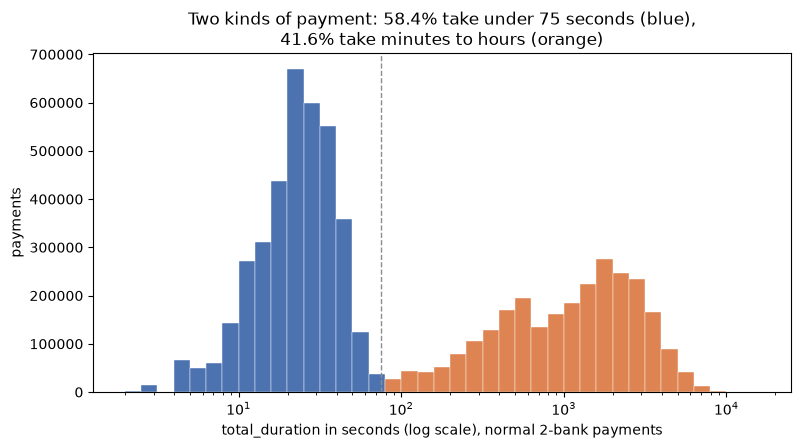

Normal 2-bank payments: 6,318,885 | 75 s or less: 58.41%


In [4]:
hist = q("""
    SELECT floor(log10(seconds) * 10) / 10 AS log_bin, count(*) AS n
    FROM direct WHERE anomaly_type IS NULL GROUP BY 1 ORDER BY 1
""")
n_direct = int(hist.n.sum())
fast_share = float(q(f"SELECT avg((seconds <= {SLOW_SECONDS})::INT) AS p FROM direct WHERE anomaly_type IS NULL").loc[0, "p"])

fig, ax = plt.subplots(figsize=(9, 4.4))
left = 10 ** hist.log_bin
ax.bar(left, hist.n, width=10 ** (hist.log_bin + 0.1) - left, align="edge",
       color=[BLUE if l < SLOW_SECONDS else ORANGE for l in left], edgecolor="white", linewidth=0.3)
ax.axvline(SLOW_SECONDS, color=GREY, ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("total_duration in seconds (log scale), normal 2-bank payments")
ax.set_ylabel("payments")
ax.set_title(f"Two kinds of payment: {100 * fast_share:.1f}% take under {SLOW_SECONDS} seconds (blue),\n"
             f"{100 * (1 - fast_share):.1f}% take minutes to hours (orange)")
eda.save(fig, "D1_two_speeds")
plt.show()
print(f"Normal 2-bank payments: {n_direct:,} | {SLOW_SECONDS} s or less: {100 * fast_share:.2f}%")

**Result: H-D2 held; H-D1 held only for the averages.** The mean rises by a nearly constant amount for each extra bank, and so does the variance (last two columns), which is what a sum of independent pieces would give. But the durations are not "a base plus a little": they form two separate humps, so the average hides the real structure.

## 3. What makes a payment slow? (H-D3, H-D4)

Baseline: the share of normal 2-bank payments above 75 seconds. If hour, weekday, amount, gaps or conversions mattered, the share would move with them.

In [5]:
def slow_by(dimension, label, order="segment", where="TRUE"):
    return q(f"""
        SELECT '{label}' AS dimension, CAST({dimension} AS VARCHAR) AS segment, count(*) AS n,
               100 * avg((seconds > {SLOW_SECONDS})::INT) AS pct_slow, median(seconds) AS median_s
        FROM direct WHERE anomaly_type IS NULL AND {where} GROUP BY 2 ORDER BY {order}
    """)

slow = pd.concat([
    slow_by("CASE WHEN utc_hour < 6 THEN '00-05' WHEN utc_hour < 12 THEN '06-11' WHEN utc_hour < 18 THEN '12-17' ELSE '18-23' END", "hour (UTC)"),
    slow_by("utc_is_weekend", "weekend (UTC)"),
    slow_by("gaps", "gaps in path", where="gaps <= 2"),
    slow_by("conversions", "currency conversions"),
    slow_by("party_pair", "party pair"),
    slow_by("usd_amount_magnitude", "amount, power of 10", order="CAST(segment AS INT)", where="usd_amount_magnitude BETWEEN 0 AND 6"),
], ignore_index=True)
slow["difference_pp"] = slow.pct_slow - 100 * (1 - fast_share)
print(f"Baseline: {100 * (1 - fast_share):.2f}% of normal 2-bank payments are slow")
slow.round(2)

Baseline: 41.59% of normal 2-bank payments are slow


,dimension,segment,n,pct_slow,median_s,difference_pp
0,hour (UTC),00-05,980801,41.070,39.000,-0.520
1,hour (UTC),06-11,1768857,42.110,40.000,0.520
2,hour (UTC),12-17,2065369,41.620,39.000,0.030
3,hour (UTC),18-23,1503858,41.280,39.000,-0.310
4,weekend (UTC),false,5612122,41.620,39.000,0.030
5,weekend (UTC),true,706763,41.350,39.000,-0.240
6,gaps in path,0,6003843,41.590,39.000,-0.000
7,gaps in path,1,299199,41.620,39.000,0.030
8,gaps in path,2,15070,41.690,39.000,0.100
9,currency conversions,0,991450,45.530,45.000,3.940


In [6]:
bank_spread = pd.concat([
    q(f"""WITH b AS (SELECT first_bank AS bank, count(*) AS n, 100 * avg((seconds > {SLOW_SECONDS})::INT) AS pct_slow
                       FROM direct WHERE anomaly_type IS NULL GROUP BY 1 HAVING count(*) >= 5000)
            SELECT 'first bank' AS grouped_by, count(*) AS groups_with_5000_plus_payments, min(pct_slow) AS lowest_pct_slow,
                   quantile_cont(pct_slow, 0.1) AS p10, median(pct_slow) AS median_pct_slow, quantile_cont(pct_slow, 0.9) AS p90,
                   max(pct_slow) AS highest_pct_slow FROM b"""),
    q(f"""WITH b AS (SELECT last_bank AS bank, count(*) AS n, 100 * avg((seconds > {SLOW_SECONDS})::INT) AS pct_slow
                       FROM direct WHERE anomaly_type IS NULL GROUP BY 1 HAVING count(*) >= 5000)
            SELECT 'last bank' AS grouped_by, count(*) AS groups_with_5000_plus_payments, min(pct_slow) AS lowest_pct_slow,
                   quantile_cont(pct_slow, 0.1) AS p10, median(pct_slow) AS median_pct_slow, quantile_cont(pct_slow, 0.9) AS p90,
                   max(pct_slow) AS highest_pct_slow FROM b"""),
], ignore_index=True)
bank_spread.round(1)

,grouped_by,groups_with_5000_plus_payments,lowest_pct_slow,p10,median_pct_slow,p90,highest_pct_slow
0,first bank,283,3.000,11.800,19.300,26.200,99.900
1,last bank,316,11.300,21.000,28.600,37.700,100.000


Hour, weekday, gaps and party pair move the slow share by about a point or less; conversions and amount by a few points. Between **banks**, the share ranges from almost none to all. So the next step is the pair of banks.

For every ordered pair of banks with at least 300 normal 2-bank payments: what share of the pair's payments is slow?

Pairs with 300+ payments: 1,692 | all fast: 695 | all slow: 893 | within 5 points of all-fast or all-slow: 94 | in between: 10


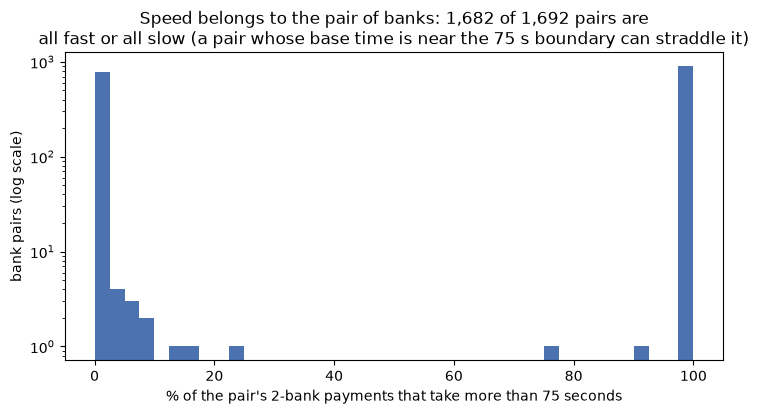

,first_bank,last_bank,n,pct_slow,fastest,median_s,slowest
796,0001MQM0,0009TNT0,14018,100.000,1586,"1,594.000",1643
1623,0032MYK0,0010ALT0,11782,0.008,17,25.000,81
748,0065SGS0,0472US30,7650,100.000,915,923.000,970
1228,0119JPJ0,0072AEA0,4881,0.123,32,40.000,85
1485,0172CHZ0,0026FIH0,4272,0.000,8,16.000,62
807,0041PAP0,0021AU20,4259,0.000,12,20.000,71
601,0098DEF0,0084ESM0,4006,0.150,29,38.000,87
121,0097IT20,0004IMD0,3930,0.000,10,18.000,70


In [7]:
pair_slow = q(f"""
    SELECT first_bank, last_bank, count(*) AS n, 100 * avg((seconds > {SLOW_SECONDS})::INT) AS pct_slow,
           min(seconds) AS fastest, median(seconds) AS median_s, max(seconds) AS slowest
    FROM direct WHERE anomaly_type IS NULL GROUP BY 1, 2 HAVING count(*) >= 300
""")
all_fast = int((pair_slow.pct_slow == 0).sum())
all_slow = int((pair_slow.pct_slow == 100).sum())
nearly = int(((pair_slow.pct_slow > 0) & (pair_slow.pct_slow < 5)).sum()) + int(((pair_slow.pct_slow > 95) & (pair_slow.pct_slow < 100)).sum())
middle = len(pair_slow) - all_fast - all_slow - nearly
print(f"Pairs with 300+ payments: {len(pair_slow):,} | all fast: {all_fast:,} | all slow: {all_slow:,} | "
      f"within 5 points of all-fast or all-slow: {nearly:,} | in between: {middle:,}")

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(pair_slow.pct_slow, bins=np.arange(0, 102.5, 2.5), color=BLUE)
ax.set_yscale("log")
ax.set_xlabel(f"% of the pair's 2-bank payments that take more than {SLOW_SECONDS} seconds")
ax.set_ylabel("bank pairs (log scale)")
ax.set_title(f"Speed belongs to the pair of banks: {all_fast + all_slow + nearly:,} of {len(pair_slow):,} pairs are\n"
             "all fast or all slow (a pair whose base time is near the 75 s boundary can straddle it)")
eda.save(fig, "D2_speed_by_bank_pair")
plt.show()
pair_slow.sort_values("n", ascending=False).head(8)

**Result: H-D3 and H-D4 were rejected as causes.** The small differences by amount or conversions are by-products of which banks are involved. The table shows why: within one pair of banks, the fastest and the slowest payment are only seconds apart, whether the pair takes 20 seconds or 40 minutes.

## 4. A fixed base per pair, plus a small random delay (H-D6, H-D7)

How much of the variation in duration between 2-bank payments is explained simply by knowing the pair of banks?

In [8]:
explained = q("""
    SELECT count(*)                                                        AS payments,
           var_pop(d.seconds)                                              AS total_variance,
           avg((d.seconds - p.mean_seconds) * (d.seconds - p.mean_seconds)) AS variance_within_pairs,
           100 * (1 - avg((d.seconds - p.mean_seconds) * (d.seconds - p.mean_seconds)) / var_pop(d.seconds)) AS pct_explained_by_pair
    FROM direct d JOIN pair_base p USING (first_bank, last_bank)
""")
print(f"Standard deviation of duration, all 2-bank payments: {math.sqrt(explained.loc[0, 'total_variance']):,.0f} s | "
      f"within one pair of banks: {math.sqrt(explained.loc[0, 'variance_within_pairs']):.1f} s")
explained.round(4)

Standard deviation of duration, all 2-bank payments: 1,133 s | within one pair of banks: 6.6 s


,payments,total_variance,variance_within_pairs,pct_explained_by_pair
0,6323280,"1,284,643.208",43.776,99.997


**The random delay.** For pairs with at least 1,000 payments, the shortest observed duration is a reliable estimate of the pair's base. Delay = duration minus that base.

In [9]:
delay = q("""
    SELECT d.seconds - p.base_seconds AS delay_s, count(*) AS n
    FROM direct d JOIN pair_base p USING (first_bank, last_bank) WHERE p.n >= 1000 GROUP BY 1 ORDER BY 1
""")
n_delay = int(delay.n.sum())
mean_delay = float((delay.delay_s * delay.n).sum() / n_delay)
var_delay = float(((delay.delay_s - mean_delay) ** 2 * delay.n).sum() / n_delay)
cum = delay.n.cumsum() / n_delay
observed_q = {p: int(delay.delay_s[cum >= p].iloc[0]) for p in (0.5, 0.9, 0.99)}

SHAPE, SCALE = 2, 5.0                                   # Gamma(shape 2, scale 5 s) = sum of two exponential delays of 5 s
gamma_cdf = lambda x: 1 - math.exp(-x / SCALE) * (1 + x / SCALE)
def gamma_quantile(p, lo=0.0, hi=200.0):
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if gamma_cdf(mid) < p else (lo, mid)
    return (lo + hi) / 2

pd.DataFrame({
    "observed delay": [n_delay, mean_delay, var_delay, observed_q[0.5], observed_q[0.9], observed_q[0.99], int(delay.delay_s.max())],
    "Gamma(shape 2, scale 5 s)": [np.nan, SHAPE * SCALE, SHAPE * SCALE ** 2, gamma_quantile(0.5), gamma_quantile(0.9), gamma_quantile(0.99), np.nan],
}, index=["payments", "mean (s)", "variance", "median (s)", "90th percentile (s)", "99th percentile (s)", "largest (s)"]).round(2)

,observed delay,"Gamma(shape 2, scale 5 s)"
payments,"408,285.000",NaN
mean (s),9.980,10.000
variance,49.820,50.000
median (s),8.000,8.390
90th percentile (s),19.000,19.450
99th percentile (s),33.000,33.190
largest (s),81.000,NaN


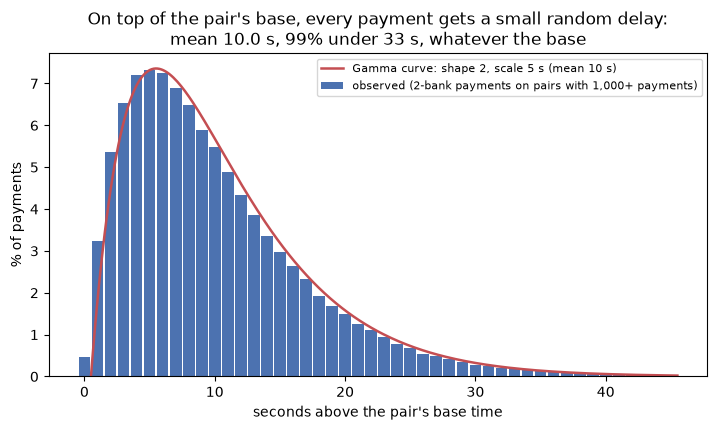

In [10]:
shown = delay[delay.delay_s <= 45]
xs = np.linspace(0, 45, 300)
density = xs / SCALE ** 2 * np.exp(-xs / SCALE)          # Gamma(2, 5) density
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(shown.delay_s, 100 * shown.n / n_delay, width=0.9, color=BLUE, label="observed (2-bank payments on pairs with 1,000+ payments)")
ax.plot(xs + 0.5, 100 * density, color=RED, lw=1.8, label="Gamma curve: shape 2, scale 5 s (mean 10 s)")
ax.set_xlabel("seconds above the pair's base time")
ax.set_ylabel("% of payments")
ax.legend(fontsize=8)
ax.set_title(f"On top of the pair's base, every payment gets a small random delay:\n"
             f"mean {mean_delay:.1f} s, 99% under {observed_q[0.99]} s, whatever the base")
eda.save(fig, "D3_random_delay")
plt.show()

**Control check.** If the delay is one fixed random draw, its average must be the same at any hour, for any amount, with or without gaps or conversions, for fast and slow pairs, and for anomalies. Pairs with 200+ payments are used here so that every segment has enough rows.

In [11]:
def delay_by(dimension, label, order="segment", where="TRUE"):
    return q(f"""
        SELECT '{label}' AS dimension, CAST({dimension} AS VARCHAR) AS segment, count(*) AS n,
               avg(d.seconds - p.base_seconds) AS mean_delay_s, median(d.seconds - p.base_seconds) AS median_delay_s
        FROM direct d JOIN pair_base p USING (first_bank, last_bank)
        WHERE p.n >= 200 AND {where} GROUP BY 2 ORDER BY {order}
    """)

pd.concat([
    delay_by("CASE WHEN p.base_seconds < 60 THEN '1. base under 1 minute' WHEN p.base_seconds < 600 THEN '2. base 1-10 minutes' ELSE '3. base over 10 minutes' END", "base time of the pair"),
    delay_by("CASE WHEN utc_hour < 6 THEN '00-05' WHEN utc_hour < 12 THEN '06-11' WHEN utc_hour < 18 THEN '12-17' ELSE '18-23' END", "hour (UTC)"),
    delay_by("utc_is_weekend", "weekend (UTC)"),
    delay_by("gaps > 0", "path has a gap"),
    delay_by("conversions", "currency conversions"),
    delay_by("usd_amount_magnitude", "amount, power of 10", order="CAST(segment AS INT)", where="usd_amount_magnitude BETWEEN 1 AND 5"),
    delay_by("CASE WHEN anomaly_type IS NULL THEN 'normal' ELSE 'anomaly' END", "label", order="segment DESC"),
], ignore_index=True).round(2)

,dimension,segment,n,mean_delay_s,median_delay_s
0,base time of the pair,1. base under 1 minute,695968,9.870,8.000
1,base time of the pair,2. base 1-10 minutes,260347,9.900,8.000
2,base time of the pair,3. base over 10 minutes,494633,9.880,8.000
3,hour (UTC),00-05,230241,9.860,8.000
4,hour (UTC),06-11,409089,9.880,8.000
5,hour (UTC),12-17,467869,9.880,8.000
6,hour (UTC),18-23,343749,9.880,8.000
7,weekend (UTC),false,1289158,9.880,8.000
8,weekend (UTC),true,161790,9.870,8.000
9,path has a gap,false,1378343,9.880,8.000


**Result: H-D6 and H-D7 held.** Knowing the two banks explains essentially all of the variation. What is left is a delay with the mean, variance and percentiles of a Gamma distribution with shape 2 and scale 5 seconds, and its average is the same in every segment.

## 5. Routes with intermediaries (H-D8, H-D9)

If every link has its own base time, a route A → B → C should take base(A, B) + base(B, C). The bases come from the 2-bank payments on the same pairs (pairs with 30+ payments), so the test is only possible where both links also exist as 2-bank routes. Routes without gaps and normal rows only.

In [12]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE multi AS
    SELECT string_split(bic8_path, ';') AS hops, participant_count AS banks, total_duration AS seconds, transaction_type_code AS route_type
    FROM feat WHERE participant_count IN (3, 4) AND path_gaps = 0 AND anomaly_type IS NULL
""")
con.execute("""
    CREATE OR REPLACE TEMP TABLE predicted AS
    SELECT 3 AS banks, m.route_type, m.seconds, l1.base_seconds + l2.base_seconds AS predicted_seconds
    FROM multi m
    JOIN pair_base l1 ON m.hops[1] = l1.first_bank AND m.hops[2] = l1.last_bank
    JOIN pair_base l2 ON m.hops[2] = l2.first_bank AND m.hops[3] = l2.last_bank
    WHERE m.banks = 3 AND l1.n >= 30 AND l2.n >= 30
    UNION ALL
    SELECT 4 AS banks, m.route_type, m.seconds, l1.base_seconds + l2.base_seconds + l3.base_seconds AS predicted_seconds
    FROM multi m
    JOIN pair_base l1 ON m.hops[1] = l1.first_bank AND m.hops[2] = l1.last_bank
    JOIN pair_base l2 ON m.hops[2] = l2.first_bank AND m.hops[3] = l2.last_bank
    JOIN pair_base l3 ON m.hops[3] = l3.first_bank AND m.hops[4] = l3.last_bank
    WHERE m.banks = 4 AND l1.n >= 30 AND l2.n >= 30 AND l3.n >= 30
""")
routes_total = q("SELECT banks, count(*) AS routes_without_gaps FROM multi GROUP BY 1 ORDER BY 1")
fit = q("""
    SELECT banks, route_type, count(*) AS routes_tested,
           median(seconds) AS median_actual_s, median(predicted_seconds) AS median_predicted_s,
           corr(seconds, predicted_seconds) AS correlation,
           avg(seconds - predicted_seconds) AS mean_difference_s,
           quantile_cont(seconds - predicted_seconds, 0.01) AS diff_p01, median(seconds - predicted_seconds) AS diff_median,
           quantile_cont(seconds - predicted_seconds, 0.99) AS diff_p99,
           100 * avg((abs(seconds - predicted_seconds) <= 30)::INT) AS pct_within_30s
    FROM predicted GROUP BY 1, 2 ORDER BY 1, 2
""")
display(routes_total)
fit.round(3)

,banks,routes_without_gaps
0,3,2096401
1,4,732983


,banks,route_type,routes_tested,median_actual_s,median_predicted_s,correlation,mean_difference_s,diff_p01,diff_median,diff_p99,pct_within_30s
0,3,Covered,51574,238.000,236.000,0.978,-0.009,-21.000,2.000,28.000,99.269
1,3,Indirect,202247,59.000,60.000,0.999,2.183,-18.000,2.000,27.000,99.412
2,4,Covered,9639,381.000,387.000,0.979,-8.181,-33.000,-5.000,22.000,98.216
3,4,Indirect,34608,256.000,261.000,0.993,-6.769,-31.000,-5.000,22.000,98.547


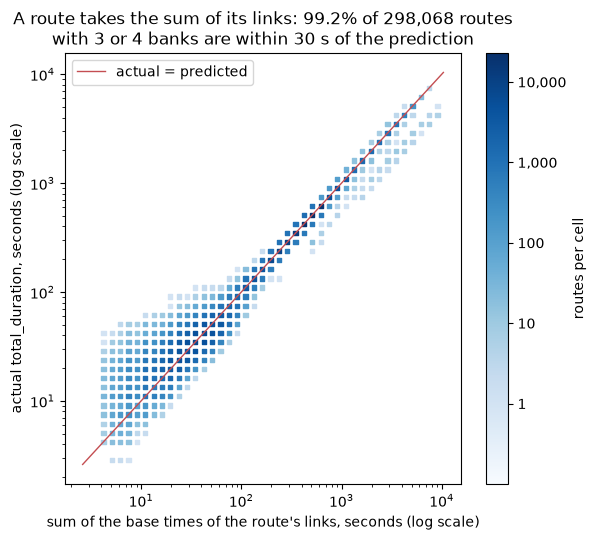

In [13]:
grid = q("""
    SELECT floor(log10(predicted_seconds) * 12) / 12 AS x, floor(log10(seconds) * 12) / 12 AS y, count(*) AS n
    FROM predicted GROUP BY 1, 2
""")
within = float(q("SELECT 100 * avg((abs(seconds - predicted_seconds) <= 30)::INT) AS p FROM predicted").loc[0, "p"])
n_pred = int(grid.n.sum())
fig, ax = plt.subplots(figsize=(6.4, 5.6))
sc = ax.scatter(10 ** (grid.x + 1 / 24), 10 ** (grid.y + 1 / 24), c=np.log10(grid.n), s=9, marker="s", cmap="Blues", vmin=-1)
lims = [min(grid.x.min(), grid.y.min()), max(grid.x.max(), grid.y.max()) + 0.1]
ax.plot([10 ** lims[0], 10 ** lims[1]], [10 ** lims[0], 10 ** lims[1]], color=RED, lw=1, label="actual = predicted")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("sum of the base times of the route's links, seconds (log scale)")
ax.set_ylabel("actual total_duration, seconds (log scale)")
ax.legend(loc="upper left")
cbar = fig.colorbar(sc, ax=ax, ticks=[0, 1, 2, 3, 4])
cbar.ax.set_yticklabels(["1", "10", "100", "1,000", "10,000"])
cbar.set_label("routes per cell")
ax.set_title(f"A route takes the sum of its links: {within:.1f}% of {n_pred:,} routes\nwith 3 or 4 banks are within 30 s of the prediction")
eda.save(fig, "D4_sum_of_links")
plt.show()

**Result: H-D8 and H-D9 held.** The prediction uses nothing but 2-bank payments on other rows, and it lands within seconds for 3-bank and 4-bank routes alike. `Indirect` and `Covered` routes fit equally well, so the label adds no time of its own: `Covered` routes are slower on average only because of the banks they connect.

The leftover (actual minus predicted) is smaller than the 10-second delay of a 2-bank payment, shrinks with every extra link and can be negative, so the random delay is **not** simply added once per link. That detail is listed as unexplained.

## 6. How are the base times distributed?

Base times of all pairs with 30+ payments (so the base is well estimated).

,base_time,pairs,payments,lowest,median_base,highest,pct_of_pairs,pct_of_payments
0,1. under 50 s,22570,"1,967,880.000",2,15.000,49,65.200,56.900
1,2. 50 to 649 s,5272,"617,564.000",50,336.000,649,15.200,17.900
2,3. 650 s and above,6781,"872,870.000",650,"1,849.000",11227,19.600,25.200


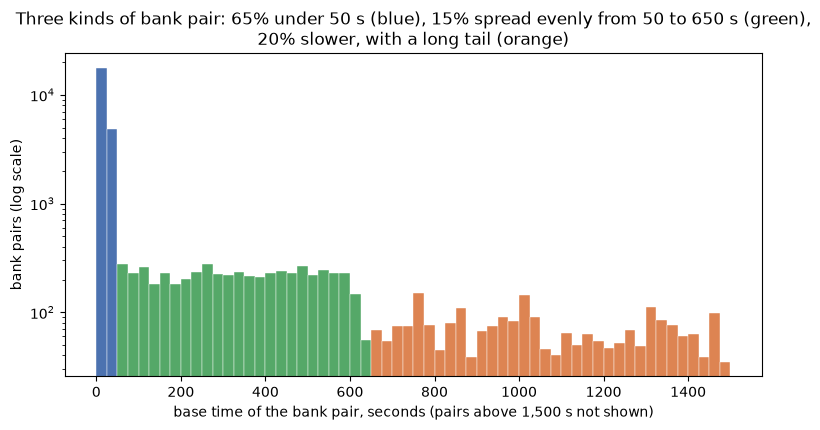

In [14]:
zones = q("""
    SELECT CASE WHEN base_seconds < 50 THEN '1. under 50 s' WHEN base_seconds < 650 THEN '2. 50 to 649 s'
                ELSE '3. 650 s and above' END AS base_time, count(*) AS pairs, sum(n) AS payments,
           min(base_seconds) AS lowest, median(base_seconds) AS median_base, max(base_seconds) AS highest
    FROM pair_base WHERE n >= 30 GROUP BY 1 ORDER BY 1
""")
zones["pct_of_pairs"] = 100 * zones.pairs / zones.pairs.sum()
zones["pct_of_payments"] = 100 * zones.payments / zones.payments.sum()
display(zones.round(1))
bins = q("""
    SELECT floor(base_seconds / 25) * 25 AS bin_start, count(*) AS pairs
    FROM pair_base WHERE n >= 30 AND base_seconds < 1500 GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(bins.bin_start, bins.pairs, width=25, align="edge",
       color=[BLUE if b < 50 else (GREEN if b < 650 else ORANGE) for b in bins.bin_start], edgecolor="white", linewidth=0.3)
ax.set_yscale("log")
ax.set_xlabel("base time of the bank pair, seconds (pairs above 1,500 s not shown)")
ax.set_ylabel("bank pairs (log scale)")
z = zones.set_index("base_time").pct_of_pairs.reindex(["1. under 50 s", "2. 50 to 649 s", "3. 650 s and above"], fill_value=0)
ax.set_title(f"Three kinds of bank pair: {z.iloc[0]:.0f}% under 50 s (blue), {z.iloc[1]:.0f}% spread evenly from 50 to 650 s (green),\n"
             f"{z.iloc[2]:.0f}% slower, with a long tail (orange)")
eda.save(fig, "D5_base_time_of_pairs")
plt.show()

The slow zone is not spread over all banks. For each first bank with 30+ partner pairs, its **fastest** pair shows whether the bank itself is slow:

In [15]:
q("""
    WITH b AS (SELECT first_bank, min(base_seconds) AS fastest_pair_s, count(*) AS partner_pairs, sum(n) AS payments
               FROM pair_base WHERE n >= 5 GROUP BY 1 HAVING count(*) >= 30)
    SELECT CASE WHEN fastest_pair_s < 50 THEN '1. fastest pair under 50 s' WHEN fastest_pair_s < 650 THEN '2. fastest pair 50 to 649 s'
                ELSE '3. fastest pair 650 s or more (a slow bank)' END AS first_bank_kind,
           count(*) AS banks, sum(partner_pairs) AS pairs, sum(payments) AS two_bank_payments,
           median(fastest_pair_s) AS median_fastest_pair_s
    FROM b GROUP BY 1 ORDER BY 1
""")

,first_bank_kind,banks,pairs,two_bank_payments,median_fastest_pair_s
0,1. fastest pair under 50 s,617,"161,425.000","3,443,704.000",3.000
1,2. fastest pair 50 to 649 s,59,"3,855.000","82,190.000",374.000
2,3. fastest pair 650 s or more (a slow bank),211,"13,376.000","274,991.000","1,643.000"


## 7. Why are scam payments slower? (H-D5)

Notebook 02 (rule R-A7) found scam payments settling far more slowly than normal ones on the same route type. If the generator adds a delay to scams, a scam payment should take longer than normal payments **on the same pair of banks**.

In [16]:
an = q("""
    SELECT d.anomaly_type,
           count(*)                                                              AS two_bank_rows,
           median(d.seconds)                                                     AS median_duration_s,
           count(*) FILTER (WHERE p.n_normal >= 5)                               AS rows_on_a_pair_with_normal_history,
           median(d.seconds - p.base_seconds_normal) FILTER (WHERE p.n_normal >= 5) AS median_s_above_normal_base,
           quantile_cont(d.seconds - p.base_seconds_normal, 0.9) FILTER (WHERE p.n_normal >= 5) AS p90_s_above_normal_base
    FROM direct d JOIN pair_base p USING (first_bank, last_bank)
    WHERE d.anomaly_type IS NOT NULL GROUP BY 1 ORDER BY 2 DESC
""")
an["pct_with_normal_history"] = 100 * an.rows_on_a_pair_with_normal_history / an.two_bank_rows
display(an.round(1))
# Pairs used only by anomalies: is the duration still constant within the pair?
q("""
    WITH s AS (SELECT d.anomaly_type, d.first_bank, d.last_bank, count(*) AS n, max(d.seconds) - min(d.seconds) AS spread_s, min(d.seconds) AS base_s
               FROM direct d JOIN pair_base p USING (first_bank, last_bank)
               WHERE d.anomaly_type IS NOT NULL AND p.n_normal = 0 GROUP BY 1, 2, 3 HAVING count(*) >= 2)
    SELECT anomaly_type, count(*) AS anomaly_only_pairs_with_2_plus_rows, sum(n) AS payments,
           median(spread_s) AS median_spread_within_pair_s, quantile_cont(spread_s, 0.9) AS p90_spread_s, median(base_s) AS median_base_s
    FROM s GROUP BY 1 ORDER BY 2 DESC
""").round(1)

,anomaly_type,two_bank_rows,median_duration_s,rows_on_a_pair_with_normal_history,median_s_above_normal_base,p90_s_above_normal_base,pct_with_normal_history
0,ROMANCE_SCAM,1494,"1,102.000",116,13.000,21.000,7.800
1,FAT_FINGER_MISTAKE,1271,40.000,1051,7.000,19.000,82.700
2,CEO_SCAM,592,648.000,107,8.000,21.400,18.100
3,ACCOUNT_REPLACEMENT_SCAM,443,454.000,85,6.000,18.600,19.200
4,DUPLICATE_PAYMENT,408,50.500,351,8.000,21.000,86.000
5,CUSTOMER_RECALL,187,41.000,151,7.000,17.000,80.700


,anomaly_type,anomaly_only_pairs_with_2_plus_rows,payments,median_spread_within_pair_s,p90_spread_s,median_base_s
0,ROMANCE_SCAM,245,"1,181.000",0.000,0.000,"1,319.000"
1,DUPLICATE_PAYMENT,2,8.000,0.000,0.000,676.000
2,ACCOUNT_REPLACEMENT_SCAM,1,2.000,1.000,1.000,741.000


**Result: H-D5 was only partly right.** Where a scam payment runs on a pair of banks that normal payments also use, it takes the pair's normal time plus the usual few seconds (third-last column of the first table). But most scam rows sit on pairs that no normal payment uses (last column), and there every payment of the pair takes exactly the same number of seconds (second table: spread 0), with a long base. So scams are not "normal payments with a delay added": their duration comes with the pair they are placed on, and on scam-only pairs they do not even receive the random delay.

## 8. Results: reconstructed rules (all checked on 10,000,000 rows)

Every number below is printed by a cell above.

### The duration recipe

1. Every ordered pair of banks (A → B) has a fixed **base time**.
2. A 2-bank payment takes the base time of its pair plus a small random delay (mean 10 s).
3. A payment with intermediaries takes the sum of the base times of its consecutive links.
4. Nothing else changes the duration: not the hour, the day, the amount, the parties, the currency conversions, the gaps in the path or the `Covered` label.

### Rules

| ID | Rule: condition → effect | Size and scope | Evidence | Confidence |
|---|---|---|---|---|
| R-D1 | For a 2-bank payment, the duration is fixed by the ordered pair (first bank, last bank). | The pair explains 99.997% of the variation: standard deviation 1,133 s across all 6,323,280 two-bank payments, 6.6 s within a pair. Of 1,692 pairs with 300+ payments, 1,682 are all fast, all slow, or within 5 points of that. | Sections 3 and 4, chart D2 | High |
| R-D2 | On top of the base, each 2-bank payment gets one random delay with the mean, variance and percentiles of a Gamma distribution (shape 2, scale 5 s). | Observed mean 9.98 s (Gamma: 10), variance 49.82 (50), median 8 s (8.39), 90th percentile 19 s (19.45), 99th 33 s (33.19); 408,285 payments. The average delay is 9.74 to 9.90 s in every segment tested (base under a minute or over 10 minutes, any hour, weekend, gaps, conversions, amount, anomaly). | Section 4, chart D3 | High for mean and spread; medium for the exact distribution (whole-second rounding not pinned down). |
| R-D3 | For 3 or 4 banks, duration = sum of the base times of the consecutive links. | Within 30 s of the sum for 99.4% (3 banks, Indirect), 99.3% (3 banks, Covered), 98.5% and 98.2% (4 banks). Tested on the 298,068 gap-free normal routes whose links all have 30+ two-bank payments. | Section 5, chart D4 | High where tested. Not tested for 5+ banks or for links never seen as a 2-bank route. |
| R-D4 | The `Covered` label, gaps and currency conversions add no time. | Covered and Indirect fit R-D3 equally well. Slow share with 0, 1, 2 gaps: 41.59%, 41.62%, 41.69%. Average delay with and without a gap: 9.84 s and 9.88 s. | Sections 3 to 5 | High |
| R-D5 | Hour of day and weekend do not affect duration. | Slow share within 0.52 points of 41.59% for every 6-hour block and for weekends. | Section 3 | High |
| R-D6 | Base times come in three kinds: fast, medium and slow. | Pairs with 30+ payments: 65.2% under 50 s (median 15 s); 15.2% spread evenly between 50 and 649 s; 19.6% at 650 s or more (median 1,849 s, up to 11,227 s). 211 of 887 first banks have no pair faster than 650 s. | Section 6, chart D5 | Medium: the three zones are observed, the rule that assigns a pair to a zone is not reconstructed. |
| R-D7 | The mean duration rises by about 200 s per extra bank, and the variance by about 0.33 million. | +178, +201, +200, +195, +212, +185 s from 2 to 8 banks. | Section 2 | High. A consequence of R-D3: each extra bank adds one more link with its own base. |

### Hypotheses that did not hold

- **H-D1 as first written, "a base plus a fixed extra per bank":** true only for averages (R-D7). The extra is not fixed; it is the base time of the added link, which can be 5 seconds or an hour.
- **H-D3, gaps and conversions add time: rejected** (R-D4). Payments with 0 conversions are slow more often (45.5% against 40.9%), and small amounts too (46.2% for amounts under 10 against 39.9% for amounts in the millions). Because the pair of banks fixes the duration to within seconds (R-D1), these differences can only come from which banks those payments use.
- **H-D4, slower outside business hours and at weekends: rejected** (R-D5).
- **H-D5, scams are delayed: partly** (text above the rules).

### What is still unexplained

1. **What makes a pair fast, medium or slow** (R-D6). There are clearly slow banks, but among fast banks the base of a pair looks random and differs by direction.
2. **The leftover in R-D3 drifts.** Actual minus predicted has a median of +2 s for 3 banks and -5 s for 4 banks, against about +8 s for 2 banks. Each extra link lowers it by 7 to 8 s, as if part of every pair's base were a per-payment constant counted once too often when links are added. The shortest durations in the data (2 s) are below that constant, so this explanation is incomplete.
3. **Scam-only pairs**: why their base times are long (median 1,319 s for romance scams) and why they carry no random delay.

### What this may mean in the real world (interpretation, not observation)

- **R-D1, R-D6:** how fast two banks settle with each other depends on their relationship: banks connected for automatic processing clear in seconds, while a pair that needs manual handling or batch processing takes minutes to hours. A bank that is slow with everyone fits a bank without automated processing.
- **R-D2:** a short queueing or processing delay at each end. A Gamma distribution with shape 2 is what the sum of two independent exponential waits gives, one per bank. *Alternative:* a single delay drawn directly from that distribution; the data cannot tell.
- **R-D3:** with intermediaries the payment is processed leg by leg, so the legs add up.
- **R-D5 is where the dataset departs from reality.** Real payments wait for cut-off times, weekends and the opening hours of the receiving country. The generator has none of this, so duration says nothing about when a payment was sent.
- **Scams:** money sent to a fraudster goes to an account the victim has never paid, often at a bank outside their usual circle, so no fast relationship exists. *Alternative:* the scam rows were generated by a separate piece of code with its own durations; the missing random delay supports this second reading.

### What other dashboards can rely on

- Duration is a property of the banks on the route. A difference in duration by amount, currency, party type or anomaly label reflects which banks are involved, not an effect of that attribute.
- Notebook 02's rule R-A7 (scams settle slower on the same route type) holds as an observation; the mechanism is the pair of banks, not a delay.
